<a href="https://colab.research.google.com/github/kinhalepuja31-cmd/E-Commerce-Customer-Segmentation-RFM-Analysis-/blob/main/E_Commerce_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [2]:
df = pd.read_csv("/content/online_retail.csv")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246622 entries, 0 to 246621
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    246622 non-null  object 
 1   StockCode    246622 non-null  object 
 2   Description  245697 non-null  object 
 3   Quantity     246621 non-null  float64
 4   InvoiceDate  246621 non-null  object 
 5   UnitPrice    246621 non-null  float64
 6   CustomerID   177467 non-null  float64
 7   Country      246621 non-null  object 
dtypes: float64(3), object(5)
memory usage: 15.1+ MB


Check the missing values percentage
We requried customer ID for RFM analysis so, removw the missing null values

In [4]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,925
Quantity,1
InvoiceDate,1
UnitPrice,1
CustomerID,69155
Country,1


In [5]:
missing_percentage = (df.isnull().sum()/len(df))*100
print(missing_percentage)

missing_info = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': missing_percentage.round(2)
})

print(missing_info.sort_values(by='Percentage (%)', ascending=False))

InvoiceNo       0.000000
StockCode       0.000000
Description     0.375068
Quantity        0.000405
InvoiceDate     0.000405
UnitPrice       0.000405
CustomerID     28.040888
Country         0.000405
dtype: float64
             Missing Count  Percentage (%)
CustomerID           69155           28.04
Description            925            0.38
StockCode                0            0.00
InvoiceNo                0            0.00
Quantity                 1            0.00
InvoiceDate              1            0.00
UnitPrice                1            0.00
Country                  1            0.00


In [6]:
new_df = df.dropna(subset=['CustomerID'])

print(new_df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [7]:
df.dropna()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
246616,558709,23126,FELTCRAFT GIRL AMELIE KIT,2.0,2011-07-01 13:02:00,4.95,17338.0,United Kingdom
246617,558709,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2011-07-01 13:02:00,2.95,17338.0,United Kingdom
246618,558709,21707,FOLDING UMBRELLA BLACKBLUE POLKADOT,2.0,2011-07-01 13:02:00,4.95,17338.0,United Kingdom
246619,558709,21706,FOLDING UMBRELLA RED/WHITE POLKADOT,1.0,2011-07-01 13:02:00,4.95,17338.0,United Kingdom


In [8]:
new_df.dropna(subset=['Country'])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
246616,558709,23126,FELTCRAFT GIRL AMELIE KIT,2.0,2011-07-01 13:02:00,4.95,17338.0,United Kingdom
246617,558709,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2011-07-01 13:02:00,2.95,17338.0,United Kingdom
246618,558709,21707,FOLDING UMBRELLA BLACKBLUE POLKADOT,2.0,2011-07-01 13:02:00,4.95,17338.0,United Kingdom
246619,558709,21706,FOLDING UMBRELLA RED/WHITE POLKADOT,1.0,2011-07-01 13:02:00,4.95,17338.0,United Kingdom


In [9]:
new_df = new_df.dropna()
print(new_df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


Invoive date is having object data type so covert it into the date time.

We have give quantity and unit price so calculate the total amount.

In [10]:
new_df = new_df[(new_df['Quantity'] > 0) & (new_df['UnitPrice'] > 0)]


new_df['InvoiceDate'] = pd.to_datetime(new_df['InvoiceDate'])

new_df['TotalSum'] = new_df['Quantity'] * new_df['UnitPrice']

new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 173210 entries, 0 to 246620
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    173210 non-null  object        
 1   StockCode    173210 non-null  object        
 2   Description  173210 non-null  object        
 3   Quantity     173210 non-null  float64       
 4   InvoiceDate  173210 non-null  datetime64[ns]
 5   UnitPrice    173210 non-null  float64       
 6   CustomerID   173210 non-null  float64       
 7   Country      173210 non-null  object        
 8   TotalSum     173210 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(4)
memory usage: 13.2+ MB


1. Define a benchmark snapshot date (1 day after the absolute last transaction date in the data)
2. Group by CustomerID and aggregate transactional logs into R, F, and M metrics

    Recency: Subtract the customer's last purchase date from the snapshot date

    Frequency: Count the number of UNIQUE invoice numbers (distinct shopping trips)

    Monetary Value: Sum the total dollar amount spent by the customer

3. Rename columns to clear business metrics

4. Reset index so CustomerID becomes a regular column instead of the row index

5. Print dataset shapes and preview the final summary table

In [11]:
import datetime as dt

snapshot_date = new_df['InvoiceDate'].max() + dt.timedelta(days=1)
print(f"Analysis Snapshot Date: {snapshot_date.strftime('%Y-%m-%d')}")


rfm_df = new_df.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,


    'InvoiceNo': 'nunique',


    'TotalSum': 'sum'
})


rfm_df.columns = ['Recency', 'Frequency', 'MonetaryValue']


rfm_df = rfm_df.reset_index()


print(f"\nSuccessfully collapsed {len(new_df)} transactions into {len(rfm_df)} unique customer profiles.")
print("\n--- Preview of the RFM Summary Table ---")
print(rfm_df.head())


Analysis Snapshot Date: 2011-07-02

Successfully collapsed 173210 transactions into 2963 unique customer profiles.

--- Preview of the RFM Summary Table ---
   CustomerID  Recency  Frequency  MonetaryValue
0     12346.0      165          1       77183.60
1     12347.0       23          4        2205.95
2     12348.0       88          3        1487.24
3     12350.0      149          1         334.40
4     12352.0      101          5        1561.81


K-Mean Clustering

Standardize the features using StandardScaler

Use the Elbow Method to find the optimal number of clusters (K)

Plot the Elbow Curve using Seaborn and Matplotlib

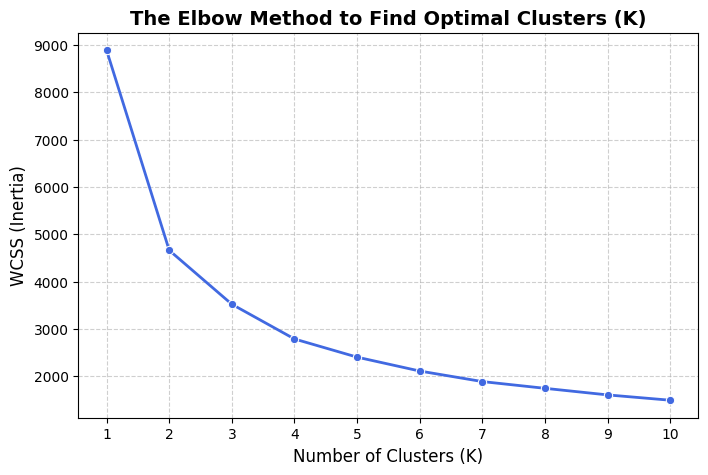

In [12]:
rfm_log = np.log(rfm_df[['Recency', 'Frequency', 'MonetaryValue']] + 1)


scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)


wcss = []                                    # Within-Cluster Sum of Squares
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))
sns.lineplot(x=list(cluster_range), y=wcss, marker='o', color='royalblue', linewidth=2)
plt.title('The Elbow Method to Find Optimal Clusters (K)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('WCSS (Inertia)', fontsize=12)
plt.xticks(list(cluster_range))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

1. Initialize and fit the final K-Means model with 4 clusters.

2. Add the resulting cluster labels back to your main RFM dataframe.

3. Calculate the average Recency, Frequency, and Monetary values for each cluster.

4. Clean up column names for readability.

In [13]:


kmeans_final = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
kmeans_final.fit(rfm_scaled)


rfm_df['Cluster'] = kmeans_final.labels_


cluster_analysis = rfm_df.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'MonetaryValue': ['mean', 'count']
}).round(1)


cluster_analysis.columns = ['Avg_Recency', 'Avg_Frequency', 'Avg_Monetary', 'Customer_Count']
print("--- Characteristics of Each Customer Cluster ---")
print(cluster_analysis)

--- Characteristics of Each Customer Cluster ---
         Avg_Recency  Avg_Frequency  Avg_Monetary  Customer_Count
Cluster                                                          
0               15.0           10.4        5765.6             382
1              121.0            1.1         286.2            1245
2               15.3            1.8         496.1             490
3               59.8            3.0        1419.4             846


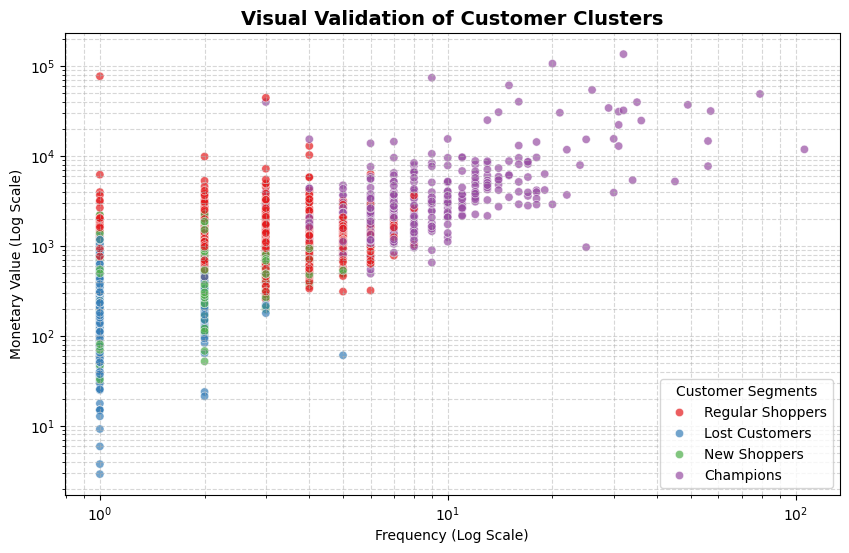

In [15]:
# 1. Map the cluster numbers to their professional business names safely

segment_map = {
    0: 'Champions',
    1: 'Lost Customers',
    2: 'New Shoppers',
    3: 'Regular Shoppers'
}
rfm_df['Segment'] = rfm_df['Cluster'].map(segment_map)

# 2. Generate the visual cluster plot

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm_df,
    x='Frequency',
    y='MonetaryValue',
    hue='Segment',
    palette='Set1',
    alpha=0.7
)
plt.title('Visual Validation of Customer Clusters', fontsize=14, fontweight='bold')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Frequency (Log Scale)')
plt.ylabel('Monetary Value (Log Scale)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Customer Segments')
plt.show()